# Exploratory Data Analysis — Fashion Product Images Dataset

**Dataset:** `paramaggarwal/fashion-product-images-dataset` (`styles.csv` + `images/`)

Goal: understand the dataset before building AE/VAE/GAN/Transformer/Diffusion stages —
class balance, missing data, text characteristics, and image properties.

In [2]:
# !pip install kagglehub[pandas-datasets] pandas matplotlib seaborn pillow wordcloud --quiet

## 0. Imports & Load Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import kagglehub

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


In [3]:
DATASET_SLUG = "paramaggarwal/fashion-product-images-dataset"

dataset_root = kagglehub.dataset_download(DATASET_SLUG)
print("Dataset root:", dataset_root)

csv_file_path = None
for root, dirs, files in os.walk(dataset_root):
    if "styles.csv" in files:
        csv_file_path = os.path.join(root, "styles.csv")
        break

df = pd.read_csv(csv_file_path, on_bad_lines="skip")
print("Shape:", df.shape)
df.head()


Using Colab cache for faster access to the 'fashion-product-images-dataset' dataset.
Dataset root: /kaggle/input/fashion-product-images-dataset
Shape: (44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


## 1. Basic Overview

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB


In [5]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,44424.0,NaN,NaN,NaN,29696.334301,17049.490518,1163.0,14768.75,28618.5,44683.25,60000.0
gender,44424,5,Men,22147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
masterCategory,44424,7,Apparel,21397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subCategory,44424,45,Topwear,15402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
articleType,44424,143,Tshirts,7067,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseColour,44409,46,Black,9728,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,44403,4,Summer,21472,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,44423.0,NaN,NaN,NaN,2012.806497,2.12648,2007.0,2011.0,2012.0,2015.0,2019.0
usage,44107,8,Casual,34406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
productDisplayName,44417,31121,Lucera Women Silver Earrings,82,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Missing Values

                    missing_count  missing_pct
usage                         317         0.71
season                         21         0.05
baseColour                     15         0.03
productDisplayName              7         0.02
year                            1         0.00


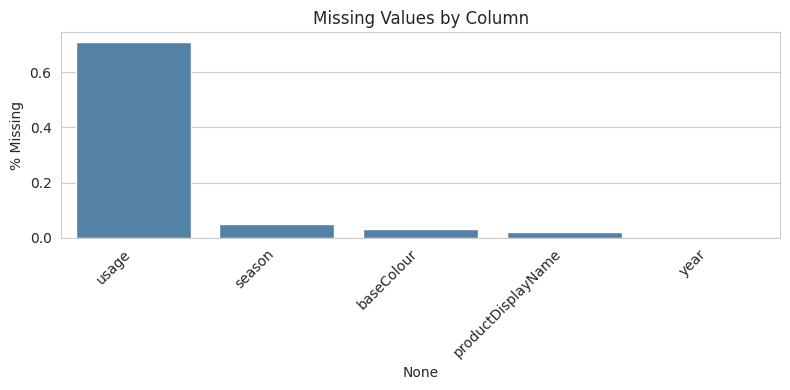

In [6]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0]
print(missing_df)

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_df.index, y=missing_df["missing_pct"], color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("% Missing")
plt.title("Missing Values by Column")
plt.tight_layout(); plt.show()


## 3. Category Distribution

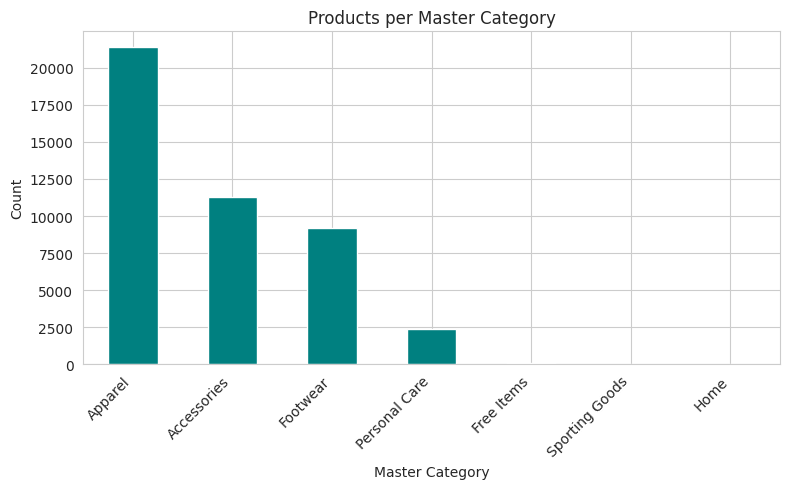

In [7]:
plt.figure(figsize=(8, 5))
df["masterCategory"].value_counts().plot(kind="bar", color="teal")
plt.title("Products per Master Category")
plt.ylabel("Count"); plt.xlabel("Master Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()


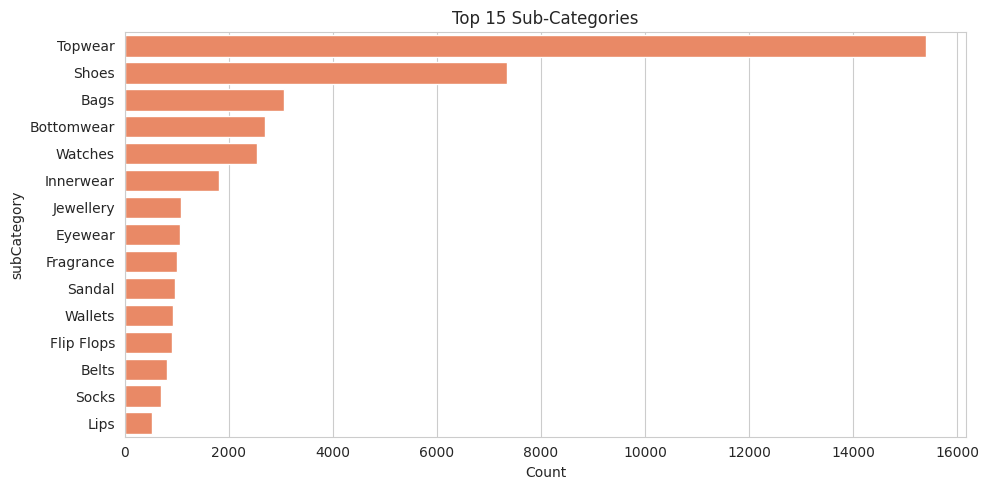

In [8]:
top_sub = df["subCategory"].value_counts().head(15)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_sub.values, y=top_sub.index, color="coral")
plt.title("Top 15 Sub-Categories")
plt.xlabel("Count")
plt.tight_layout(); plt.show()


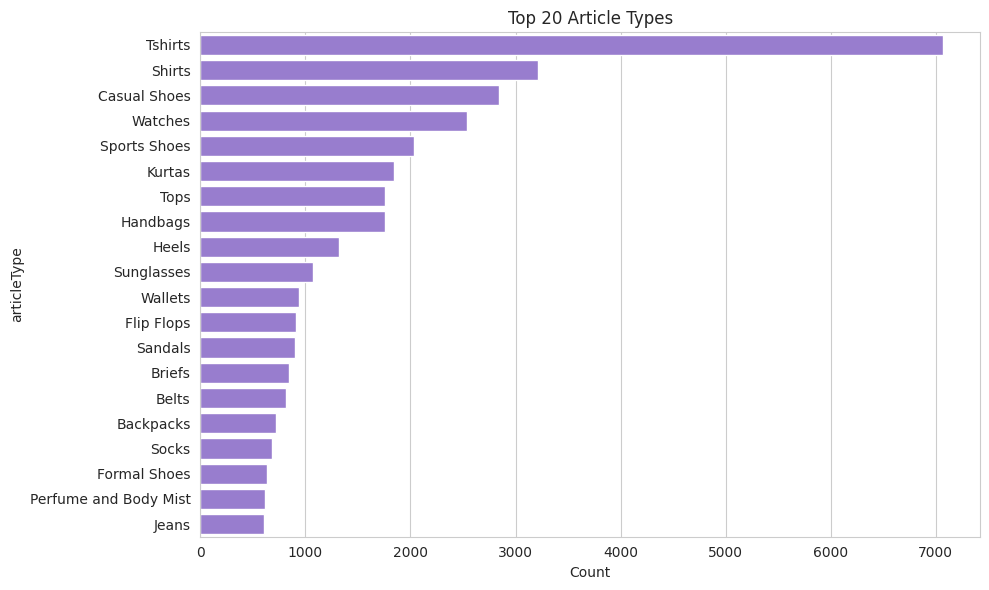

In [9]:
top_article = df["articleType"].value_counts().head(20)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_article.values, y=top_article.index, color="mediumpurple")
plt.title("Top 20 Article Types")
plt.xlabel("Count")
plt.tight_layout(); plt.show()


## 4. Gender / Target Audience Distribution

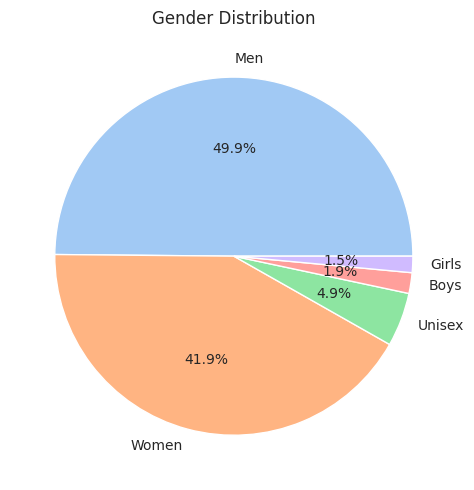

In [10]:
plt.figure(figsize=(6, 5))
colors = sns.color_palette("pastel")
df["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=colors)
plt.title("Gender Distribution")
plt.ylabel("")
plt.tight_layout(); plt.show()


## 5. Color Distribution

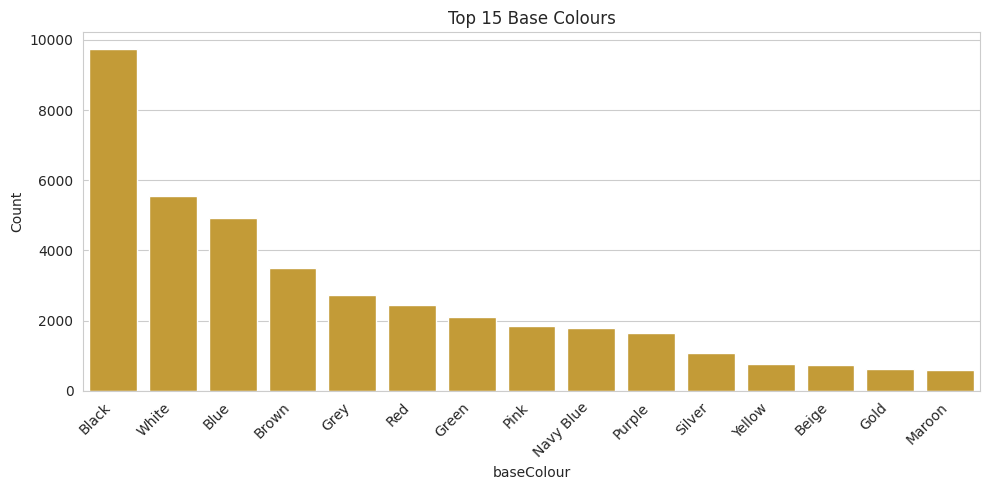

In [11]:
top_colors = df["baseColour"].value_counts().head(15)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_colors.index, y=top_colors.values, color="goldenrod")
plt.title("Top 15 Base Colours")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()


## 6. Season & Usage Distribution

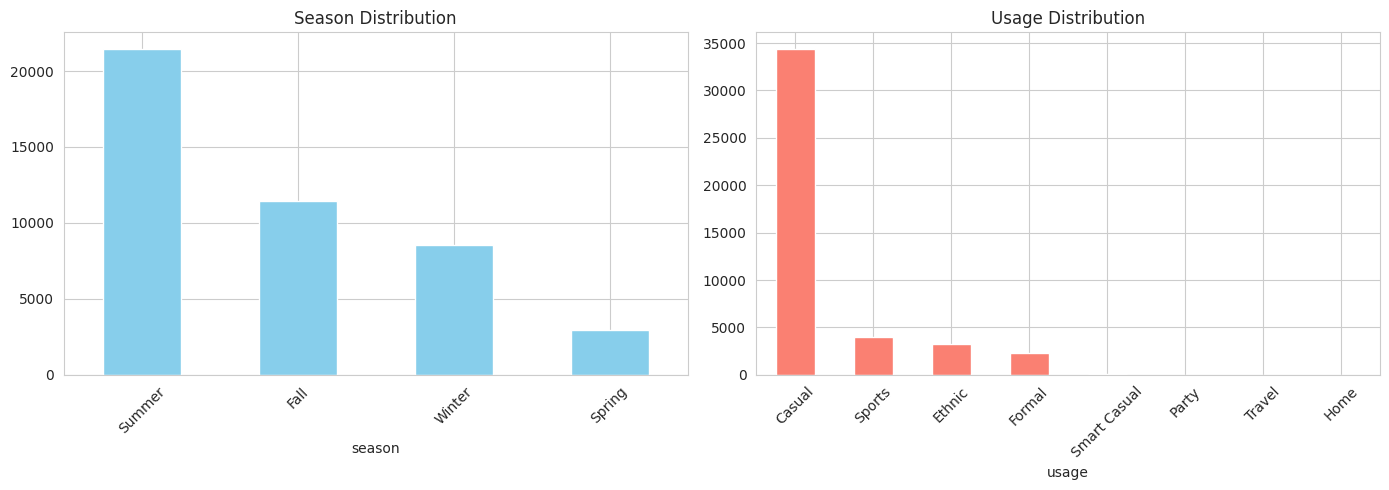

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["season"].value_counts().plot(kind="bar", ax=axes[0], color="skyblue")
axes[0].set_title("Season Distribution")
axes[0].tick_params(axis="x", rotation=45)

df["usage"].value_counts().plot(kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("Usage Distribution")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


## 7. Year Trend

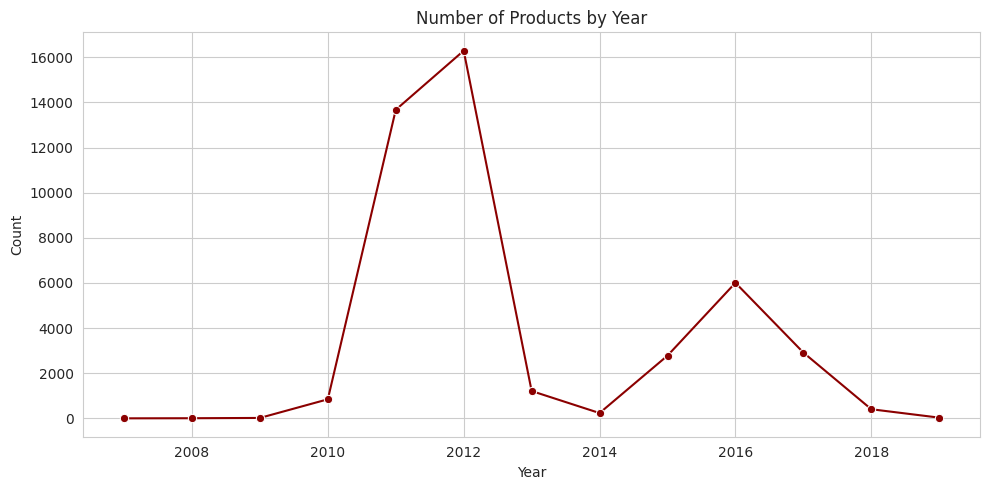

In [13]:
year_counts = df["year"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
sns.lineplot(x=year_counts.index, y=year_counts.values, marker="o", color="darkred")
plt.title("Number of Products by Year")
plt.xlabel("Year"); plt.ylabel("Count")
plt.tight_layout(); plt.show()


## 8. Product Title — Text Length Analysis

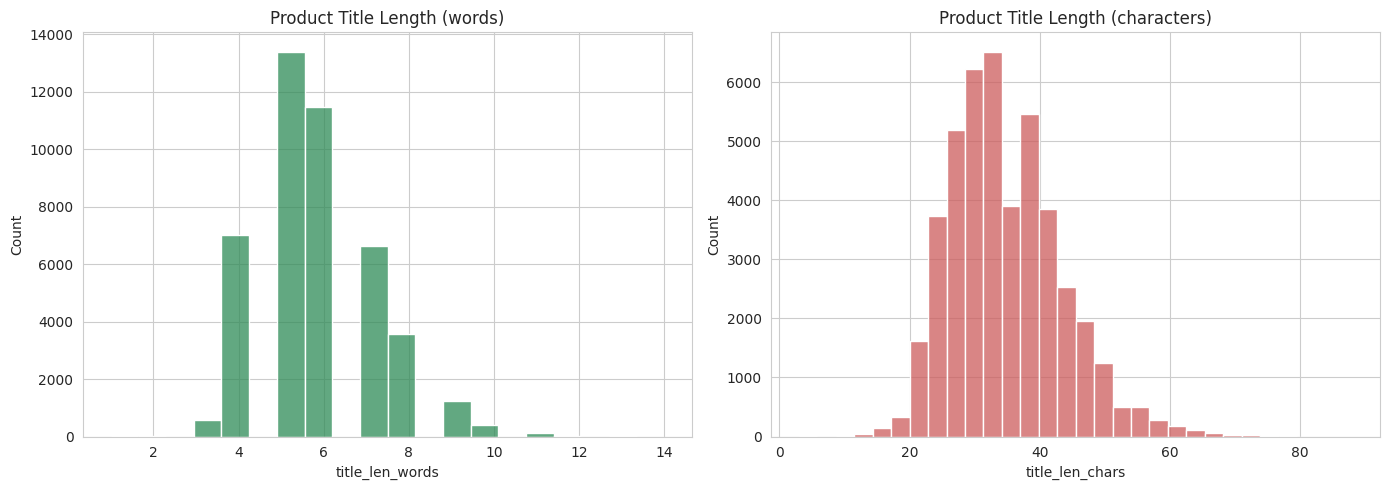

       title_len_words  title_len_chars
count     44424.000000     44424.000000
mean          5.790113        34.664618
std           1.405023         8.529014
min           1.000000         3.000000
25%           5.000000        29.000000
50%           6.000000        34.000000
75%           7.000000        40.000000
max          14.000000        88.000000


In [14]:
df["title_len_words"] = df["productDisplayName"].astype(str).apply(lambda x: len(x.split()))
df["title_len_chars"] = df["productDisplayName"].astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["title_len_words"], bins=20, ax=axes[0], color="seagreen")
axes[0].set_title("Product Title Length (words)")

sns.histplot(df["title_len_chars"], bins=30, ax=axes[1], color="indianred")
axes[1].set_title("Product Title Length (characters)")
plt.tight_layout(); plt.show()

print(df[["title_len_words", "title_len_chars"]].describe())


## 9. Word Cloud of Product Titles

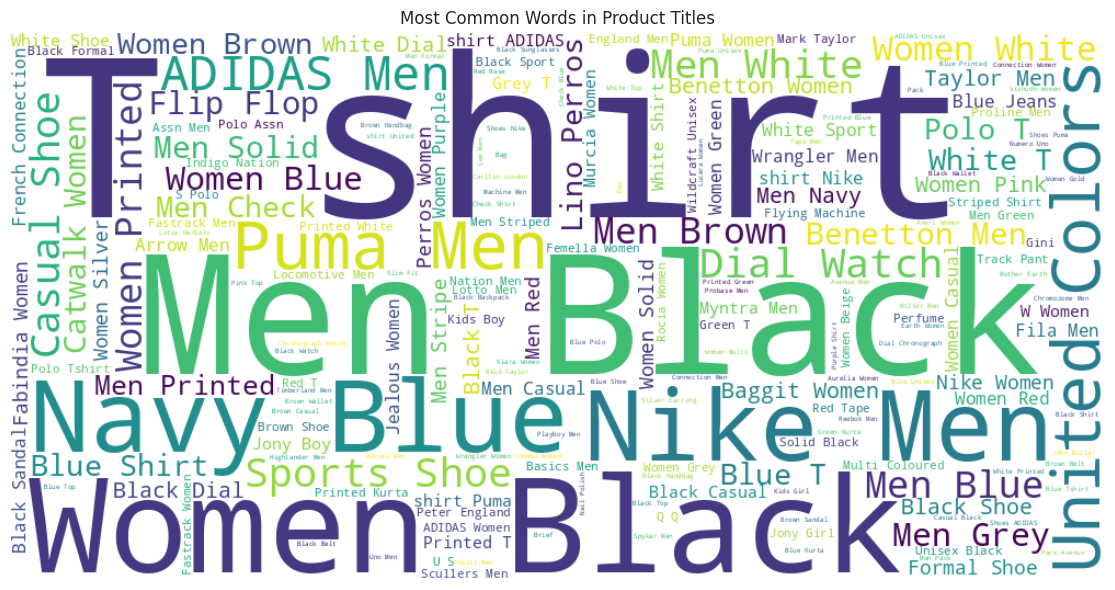

In [15]:
from wordcloud import WordCloud

text = " ".join(df["productDisplayName"].astype(str).tolist())
wc = WordCloud(width=1000, height=500, background_color="white", colormap="viridis").generate(text)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Words in Product Titles")
plt.tight_layout(); plt.show()


## 10. Category x Gender Cross-Tab (Heatmap)

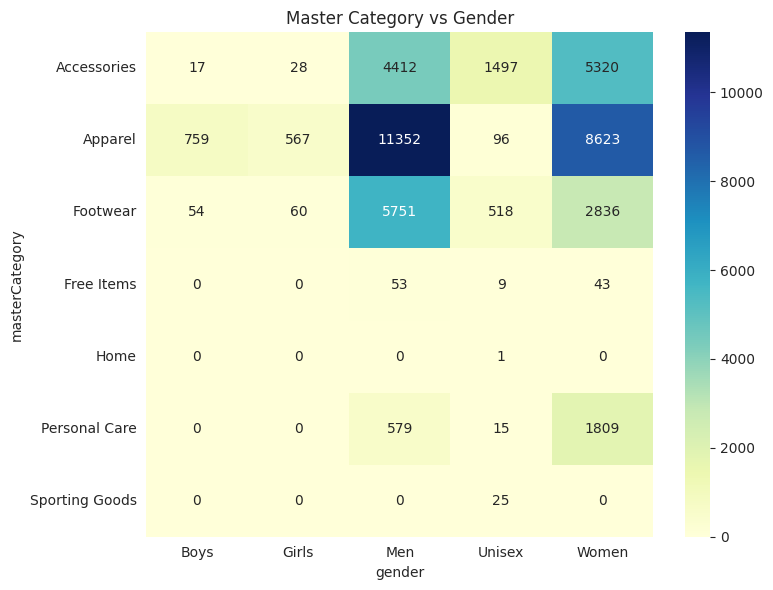

In [16]:
cross = pd.crosstab(df["masterCategory"], df["gender"])
plt.figure(figsize=(8, 6))
sns.heatmap(cross, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Master Category vs Gender")
plt.tight_layout(); plt.show()


## 11. Image Properties (Sample Check)
Samples a subset of actual image files to check resolution/aspect-ratio consistency before building AE/VAE/GAN.

In [17]:
images_dir = None
for root, dirs, files in os.walk(dataset_root):
    if "images" in dirs:
        images_dir = os.path.join(root, "images")
        break

SAMPLE_N = 500
sample_ids = df["id"].astype(str).sample(SAMPLE_N, random_state=42).tolist()

widths, heights, missing_files = [], [], 0
for pid in sample_ids:
    fpath = os.path.join(images_dir, f"{pid}.jpg")
    if os.path.exists(fpath):
        with Image.open(fpath) as im:
            w, h = im.size
            widths.append(w); heights.append(h)
    else:
        missing_files += 1

print(f"Missing image files in sample: {missing_files}/{SAMPLE_N}")
print(f"Width  -> min {min(widths)}, max {max(widths)}, mean {np.mean(widths):.1f}")
print(f"Height -> min {min(heights)}, max {max(heights)}, mean {np.mean(heights):.1f}")


Missing image files in sample: 0/500
Width  -> min 150, max 1800, mean 1374.4
Height -> min 200, max 2400, mean 1832.5


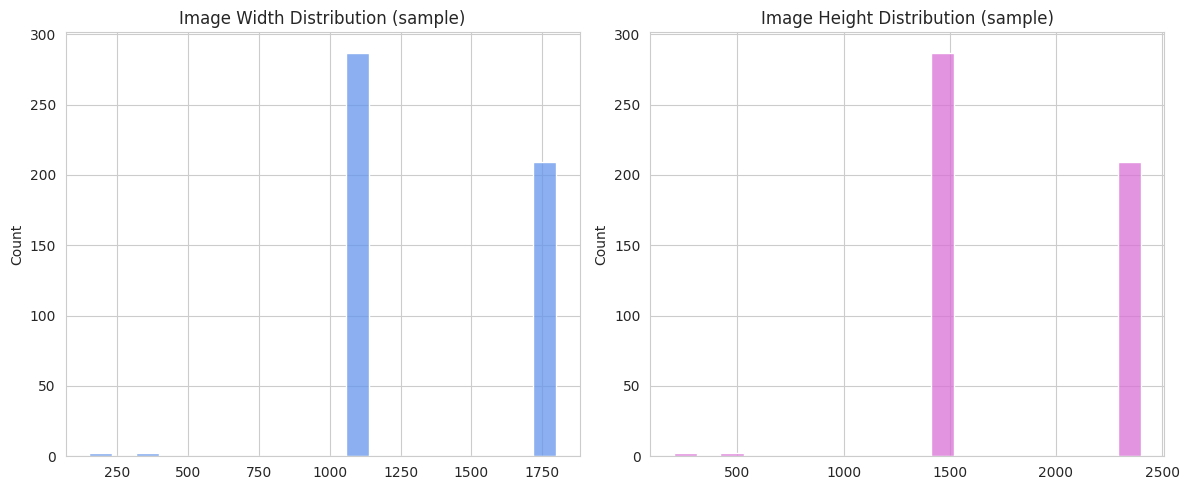

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(widths, bins=20, ax=axes[0], color="cornflowerblue")
axes[0].set_title("Image Width Distribution (sample)")
sns.histplot(heights, bins=20, ax=axes[1], color="orchid")
axes[1].set_title("Image Height Distribution (sample)")
plt.tight_layout(); plt.show()


## 12. Sample Images Grid by Category

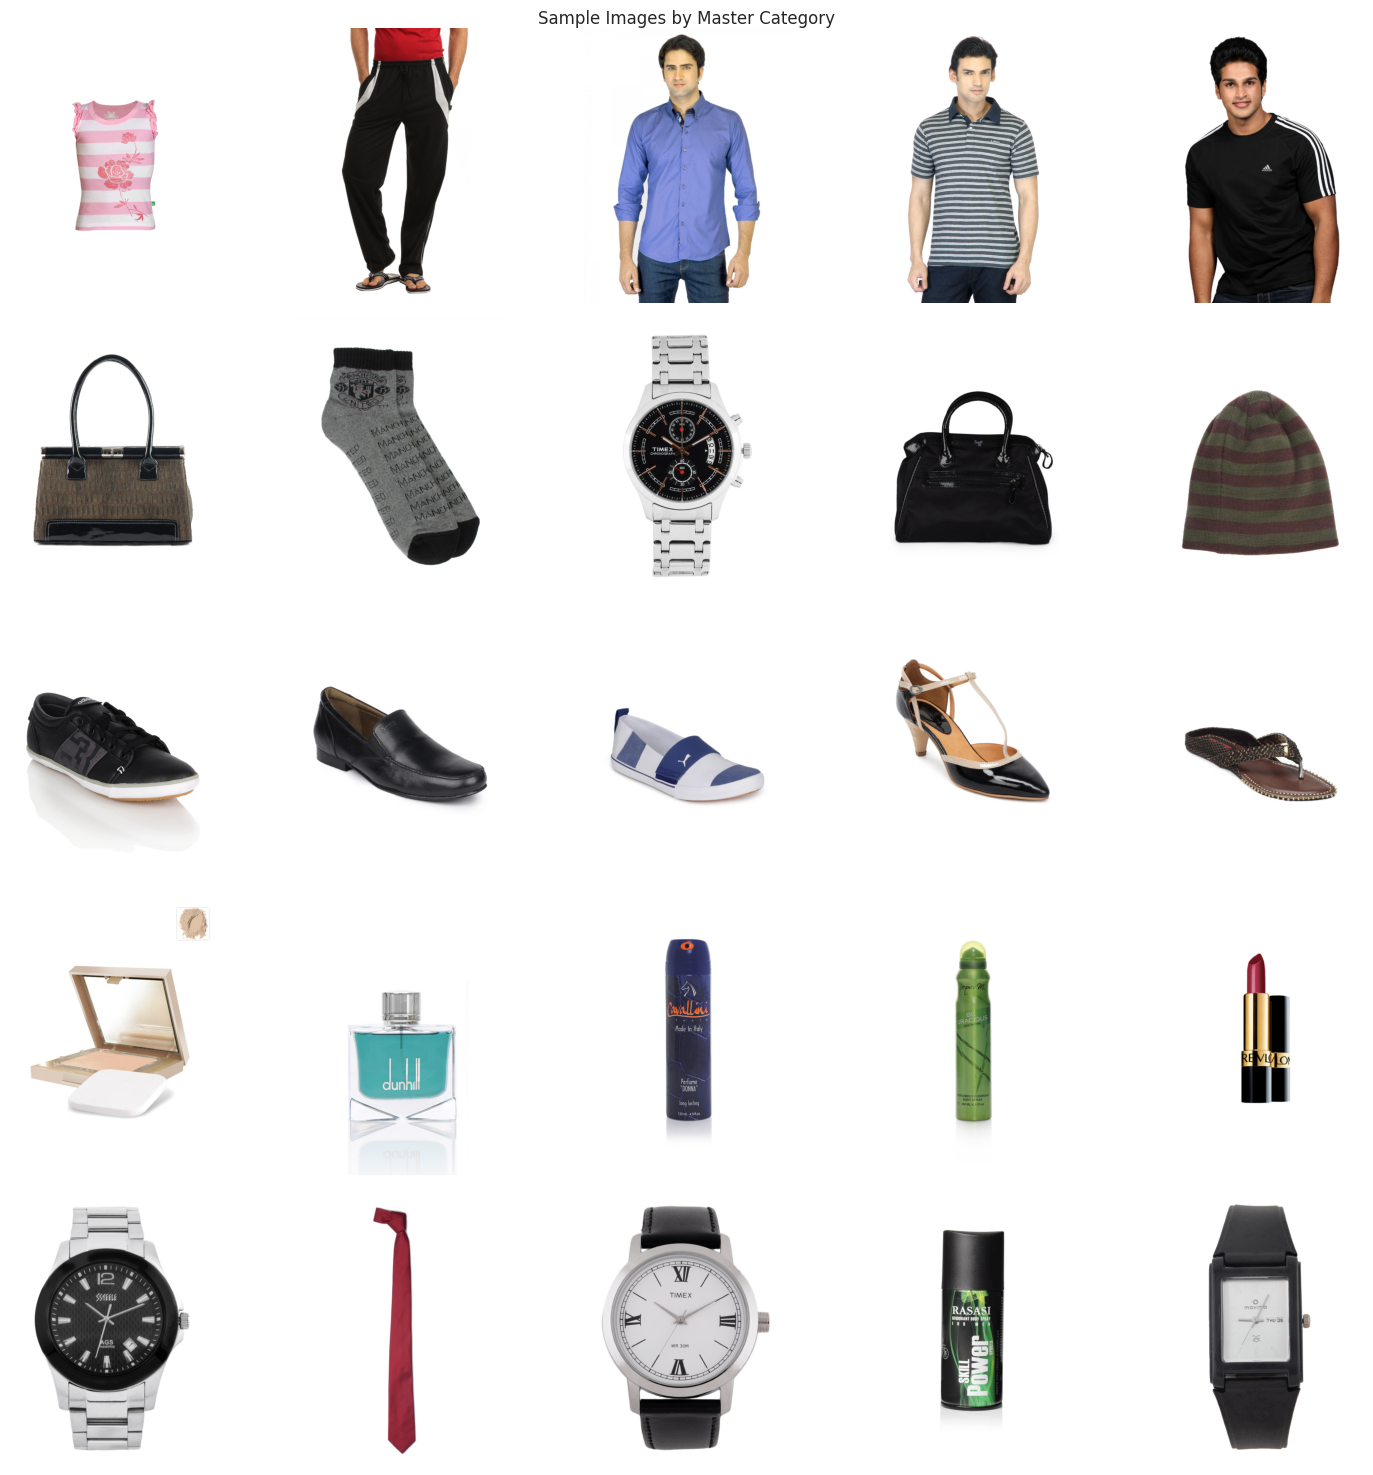

In [19]:
top_categories = df["masterCategory"].value_counts().head(5).index.tolist()

fig, axes = plt.subplots(len(top_categories), 5, figsize=(15, 3 * len(top_categories)))
for row, cat in enumerate(top_categories):
    sample_rows = df[df["masterCategory"] == cat].sample(5, random_state=1)
    for col, (_, r) in enumerate(sample_rows.iterrows()):
        fpath = os.path.join(images_dir, f"{r['id']}.jpg")
        if os.path.exists(fpath):
            img = Image.open(fpath)
            axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(cat, fontsize=10)
plt.suptitle("Sample Images by Master Category")
plt.tight_layout(); plt.show()


## 13. Duplicate Rows Check

In [20]:
dupes = df.duplicated().sum()
dupe_ids = df["id"].duplicated().sum()
print(f"Fully duplicated rows: {dupes}")
print(f"Duplicated product IDs: {dupe_ids}")


Fully duplicated rows: 0
Duplicated product IDs: 0


## 14. Summary of Findings

Fill in after running (auto-computed values shown below for convenience).

In [21]:
print(f"Total products: {len(df)}")
print(f"Master categories: {df['masterCategory'].nunique()}")
print(f"Sub-categories: {df['subCategory'].nunique()}")
print(f"Article types: {df['articleType'].nunique()}")
print(f"Colours: {df['baseColour'].nunique()}")
print(f"Year range: {df['year'].min()} - {df['year'].max()}")
print(f"Columns with missing values: {list(missing_df.index)}")
print(f"Class imbalance (top vs bottom masterCategory): "
      f"{df['masterCategory'].value_counts().max()} vs {df['masterCategory'].value_counts().min()}")


Total products: 44424
Master categories: 7
Sub-categories: 45
Article types: 143
Colours: 46
Year range: 2007.0 - 2019.0
Columns with missing values: ['usage', 'season', 'baseColour', 'productDisplayName', 'year']
Class imbalance (top vs bottom masterCategory): 21397 vs 1
